# Step 2 - Processing polarimetry with PyPolSARPro


### 1. Packages and Libraries

In [4]:
# %pip install aiohttp requests netCDF4 xarray folium shapely pillow

from shapely.geometry import Polygon
from rasterio.windows import Window
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from pystac_client import Client
from folium import GeoJson
import geopandas as gpd
from io import BytesIO
import rasterio as rio
from tqdm import tqdm
from PIL import Image
import pandas as pd
import numpy as np
import requests
import pathlib
import fsspec
import folium
import fiona
import os
from dask.diagnostics import ProgressBar
import os
import glob
import xarray as xr
import rioxarray as riox
import numpy as np

import polsar_utils as pu
from BPS_inputs_download import get_stack
from pathlib import Path

fiona.supported_drivers["KML"] = "rw"  # Enable kml driver

/home/jovyan/polsarpro/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [5]:
from polsarpro.io import open_netcdf_beam

from polsarpro.speckle_filters import refined_lee
from polsarpro.util import S_to_C3, multilook

from polsarpro.decompositions import h_a_alpha
from polsarpro.util import plot_h_alpha_plane

from polsarpro.decompositions import freeman

In [6]:
OUTPUT_DIR = Path("biomass_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

### 2. Import a single scene from a stack

In [7]:
def find_tiff_files(folder: str) -> dict:
    tiffs = sorted(
        glob.glob(os.path.join(folder, "**", "*.tif"), recursive=True)
        + glob.glob(os.path.join(folder, "**", "*.tiff"), recursive=True)
    )
    if not tiffs:
        raise FileNotFoundError(f"No .tif/.tiff files found in or under {folder}")

    abs_path = phase_path = None
    for t in tiffs:
        n = os.path.basename(t).lower()
        if any(k in n for k in ("amp", "abs", "magnitude", "amplitude")):
            abs_path = t
        elif any(k in n for k in ("phase", "ph")):
            phase_path = t

    if abs_path is None:
        abs_path = tiffs[0]
    if phase_path is None:
        phase_path = tiffs[-1] if len(tiffs) > 1 else tiffs[0]

    return {"abs": abs_path, "phase": phase_path}

def reconstruct_slc(abs_tiff: str, phase_tiff: str) -> xr.Dataset:
    """Load amp/phase TIFFs → complex SLC → PolSARpro S-matrix Dataset."""
    da_abs = riox.open_rasterio(abs_tiff, chunks={})
    da_phase = riox.open_rasterio(phase_tiff, chunks={})

    slc = da_abs * np.exp(1j * da_phase)
    dims = ("y", "x")

    return xr.Dataset(
        {
            "hh": (dims, slc[0].data),
            "hv": (dims, slc[1].data),
            "vh": (dims, slc[2].data),
            "vv": (dims, slc[3].data),
        },
        coords={"y": np.arange(slc.shape[1]), "x": np.arange(slc.shape[2])},
        attrs={"poltype": "S", "description": "Scattering matrix"},
    ).chunk("auto")

In [8]:
selected_scene = "BIO_S3_STA__1S_20260902T112810_20260902T112830_T_G01_M04_C07_T007_F250_02_DXDM9K"

In [9]:
base_dir = "biomass_inputs"
search_pattern = os.path.join(base_dir, "**", selected_scene)
matching_folders = glob.glob(search_pattern, recursive=True)

if not matching_folders:
    raise FileNotFoundError(f"Could not find folder for scene: {selected_scene}")

scene_folder = matching_folders[0]
print(f"-> Target Scene Folder: {scene_folder}")

-> Target Scene Folder: biomass_inputs/BIO_S3_STA__ID_20260815T112757_20260902T112830_T_G01_M04_S0698_W0684_A_02_DXDJ3M/L1C/BIO_S3_STA__1S_20260902T112810_20260902T112830_T_G01_M04_C07_T007_F250_02_DXDM9K


In [10]:
tiffs = find_tiff_files(scene_folder)
print(f"   - Amplitude/Magnitude file: {os.path.basename(tiffs['abs'])}")
print(f"   - Phase file: {os.path.basename(tiffs['phase'])}")

   - Amplitude/Magnitude file: bio_s3_sta__1s_20260902t112810_20260902t112830_t_g01_m04_c07_t007_f250_i_abs.tiff
   - Phase file: bio_s3_sta__1s_20260902t112810_20260902t112830_t_g01_m04_c07_t007_f250_i_phase.tiff


In [11]:
slc_dataset = reconstruct_slc(tiffs["abs"], tiffs["phase"])
print("\nSuccessfully loaded SLC Dataset:")
display(slc_dataset)

Warning 1: PROJ: proj_create_from_database: /opt/conda/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 3 whereas a number >= 7 is expected. It comes from another PROJ installation.
Warning 1: PROJ: proj_create_from_name: /opt/conda/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 3 whereas a number >= 7 is expected. It comes from another PROJ installation.
Warning 1: PROJ: proj_create_from_database: /opt/conda/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 3 whereas a number >= 7 is expected. It comes from another PROJ installation.
Warning 1: PROJ: proj_create_from_name: /opt/conda/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 3 whereas a number >= 7 is expected. It comes from another PROJ installation.



Successfully loaded SLC Dataset:


<xarray.Dataset> Size: 849MB
Dimensions:  (y: 20819, x: 1274)
Coordinates:
  * y        (y) int64 167kB 0 1 2 3 4 5 ... 20813 20814 20815 20816 20817 20818
  * x        (x) int64 10kB 0 1 2 3 4 5 6 ... 1267 1268 1269 1270 1271 1272 1273
Data variables:
    hh       (y, x) complex64 212MB dask.array<chunksize=(16560, 1013), meta=np.ndarray>
    hv       (y, x) complex64 212MB dask.array<chunksize=(16560, 1013), meta=np.ndarray>
    vh       (y, x) complex64 212MB dask.array<chunksize=(16560, 1013), meta=np.ndarray>
    vv       (y, x) complex64 212MB dask.array<chunksize=(16560, 1013), meta=np.ndarray>
Attributes:
    poltype:      S
    description:  Scattering matrix

Take out edge pixels (unvalid)

In [12]:
amp_max = xr.concat([abs(slc_dataset[p]) for p in ("hh", "hv", "vh", "vv")], dim="pol").max("pol")
sample = amp_max.isel(y=slice(0, None, 50), x=slice(0, None, 4)).compute()
thr = 1e3 * float(np.nanmedian(sample.values))
print("fill threshold:", thr)

S = slc_dataset.where(amp_max < thr)
S.attrs = slc_dataset.attrs

fill threshold: 234.43609476089478


### 3. Pauli Decomposition

In [13]:
from polsarpro.util import S_to_T3, multilook, pauli_rgb

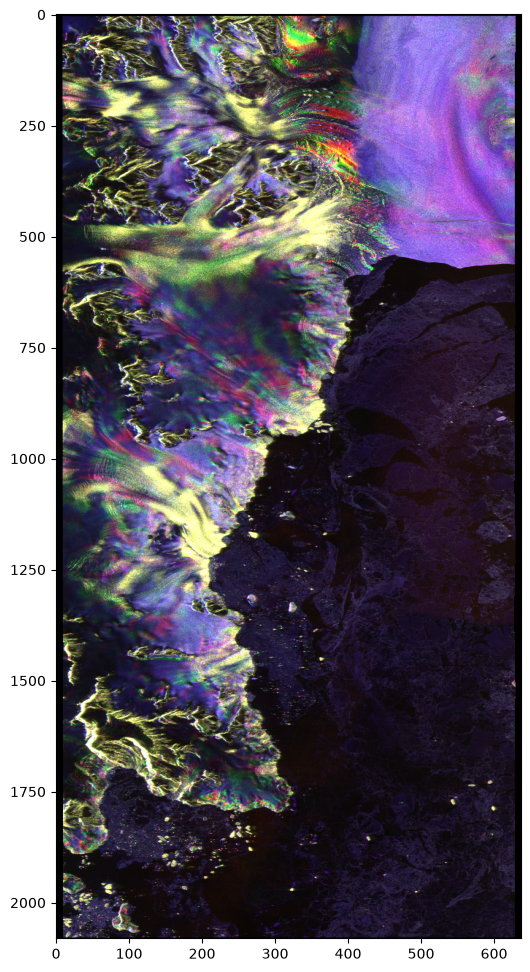

In [14]:
rgb = pauli_rgb(multilook(S_to_T3(S), dim_az=10, dim_rg=2), q=0.98).compute()

plt.figure(figsize=(6, 12))
plt.imshow(rgb.transpose("y", "x", "band").fillna(0).values, aspect="auto")
plt.show()

### 4. H/A/Alpha decomposition

In [120]:
def cloudpottier_decompose(S: xr.Dataset, out_file: str, snr: list[int] = [7, 7]) -> xr.Dataset:
    """Run H/A/Alpha decomposition and save to NetCDF."""
    from polsarpro.decompositions import h_a_alpha

    if os.path.exists(out_file):
        os.remove(out_file)

    with ProgressBar():
        h_a_alpha(S, snr).to_netcdf(out_file)

    return xr.open_dataset(out_file)

In [121]:
out_nc = os.path.join(OUTPUT_DIR, f"cloudpottier_{selected_scene}.nc")
cloudpottier = cloudpottier_decompose(S, out_nc)

[########################################] | 100% Completed | 58.18 s


In [122]:
cloudpottier

<xarray.Dataset> Size: 268MB
Dimensions:     (y: 24039, x: 928)
Coordinates:
  * y           (y) int64 192kB 0 1 2 3 4 5 ... 24034 24035 24036 24037 24038
  * x           (x) int64 7kB 0 1 2 3 4 5 6 7 ... 921 922 923 924 925 926 927
Data variables:
    entropy     (y, x) float32 89MB ...
    anisotropy  (y, x) float32 89MB ...
    alpha       (y, x) float32 89MB ...
Attributes:
    poltype:      h_a_alpha
    description:  Results of the H/A/Alpha decomposition.

In [123]:
vars_

['entropy', 'anisotropy', 'alpha']

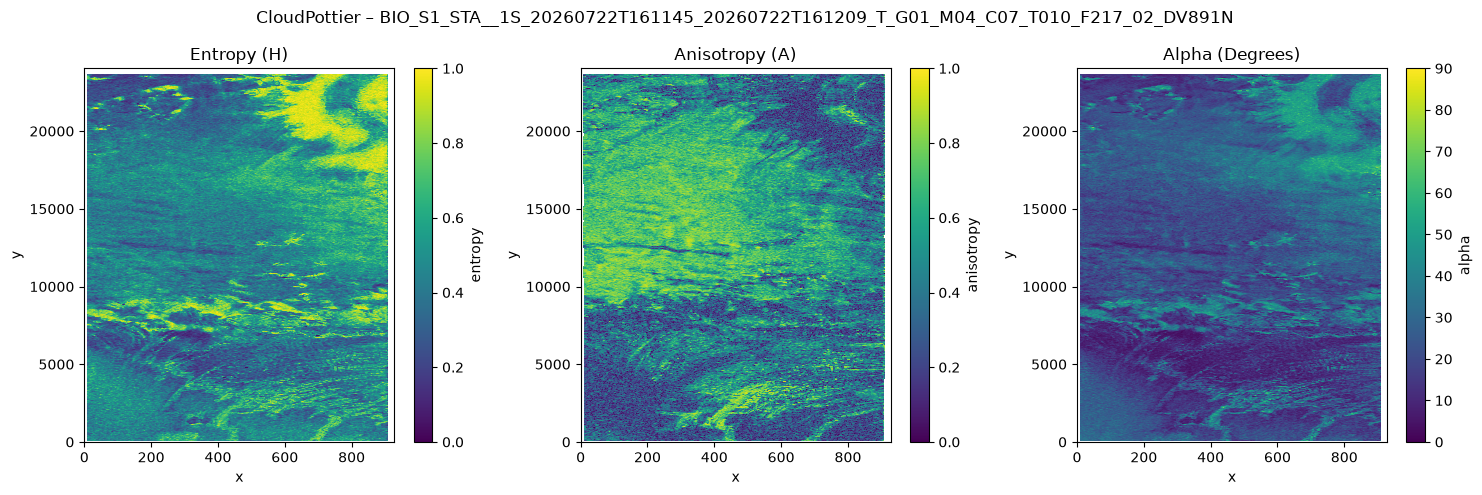

In [124]:
vars_ = [v for v in cloudpottier.data_vars if v not in ("y", "x")]

fig, axes = plt.subplots(1, len(vars_), figsize=(5 * len(vars_), 5))
if len(vars_) == 1:
    axes = [axes]
parameter_config = {
    "entropy": {"vmin": 0, "vmax": 1, "title": "Entropy (H)"},
    "anisotropy": {"vmin": 0, "vmax": 1, "title": "Anisotropy (A)"},
    "alpha": {"vmin": 0, "vmax": 90, "title": "Alpha (Degrees)"},
}
for ax, var in zip(axes, vars_):
    cfg = parameter_config.get(var, {"vmin": None, "vmax": None, "title": var})
    cloudpottier[var].plot.imshow(
        ax=ax, 
        vmin=cfg["vmin"], 
        vmax=cfg["vmax"], 
        cmap="viridis"
    )
    ax.set_title(cfg["title"])
plt.suptitle(f"CloudPottier – {selected_scene}")
plt.tight_layout()
plt.show()

### 5. Freeman-Durden decomposition

In [101]:
def freeman_decompose(S: xr.Dataset, out_file: str, snr: list[int] = [7, 7]) -> xr.Dataset:
    """Run Freeman decomposition and save to NetCDF."""
    from polsarpro.decompositions import freeman

    if os.path.exists(out_file):
        os.remove(out_file)

    with ProgressBar():
        freeman(S, snr).to_netcdf(out_file)

    return xr.open_dataset(out_file)

In [102]:
out_nc = os.path.join(OUTPUT_DIR, f"freeman_{selected_scene}.nc")
freeman = freeman_decompose(S, out_nc)

[########################################] | 100% Completed | 6.70 ss


In [103]:
freeman

<xarray.Dataset> Size: 235MB
Dimensions:  (y: 20820, x: 938)
Coordinates:
  * y        (y) int64 167kB 0 1 2 3 4 5 ... 20814 20815 20816 20817 20818 20819
  * x        (x) int64 8kB 0 1 2 3 4 5 6 7 8 ... 930 931 932 933 934 935 936 937
Data variables:
    odd      (y, x) float32 78MB ...
    double   (y, x) float32 78MB ...
    volume   (y, x) float32 78MB ...
Attributes:
    poltype:      freeman
    description:  Results of the Freeman-Durden decomposition.

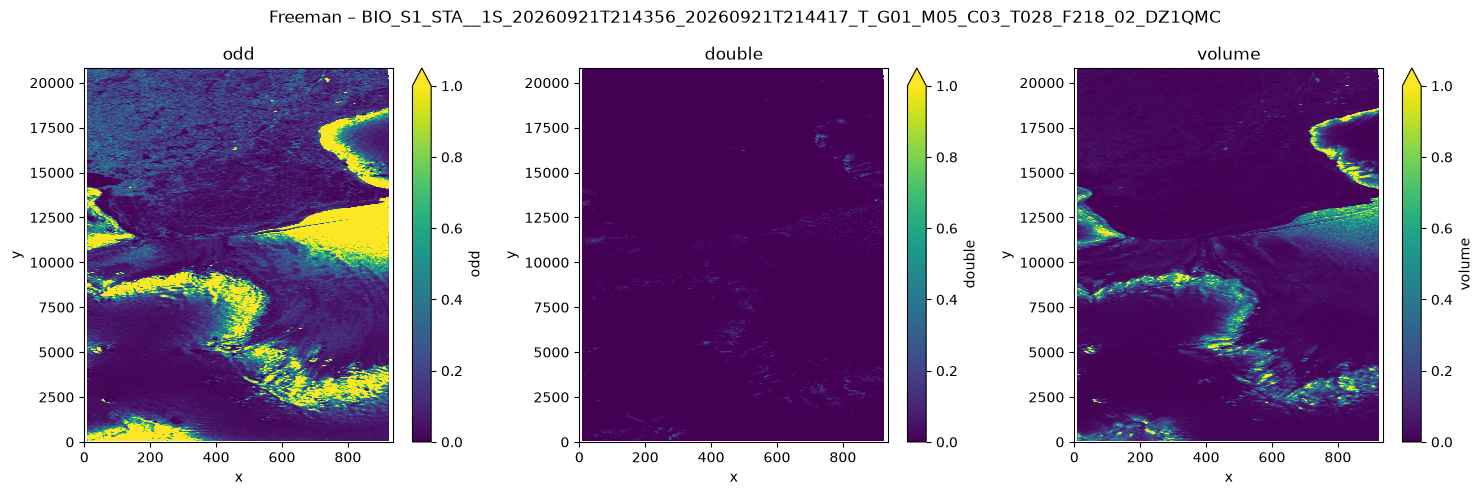

In [104]:
vars_ = [v for v in freeman.data_vars if v not in ("y", "x")]

fig, axes = plt.subplots(1, len(vars_), figsize=(5 * len(vars_), 5))
if len(vars_) == 1:
    axes = [axes]
for ax, var in zip(axes, vars_):
    freeman[var].plot.imshow(ax=ax, vmin=0, vmax=1, cmap="viridis")
    ax.set_title(var)
plt.suptitle(f"Freeman – {selected_scene}")
plt.tight_layout()
plt.show()